In [4]:
import zipfile
import os

zip_path = "/content/yawn.zip"
extract_path = "/content/yawn"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Extracted successfully")

Extracted successfully


In [5]:
for root, dirs, files in os.walk("/content/yawn"):
    print(root, "->", len(files), "files")

/content/yawn -> 0 files
/content/yawn/no yawn -> 2591 files
/content/yawn/yawn -> 2528 files


In [6]:
dataset_path = "/content/yawn"

In [7]:
for folder in os.listdir(dataset_path):
    folder_path = os.path.join(dataset_path, folder)

    if os.path.isdir(folder_path):
        print(folder, len(os.listdir(folder_path)))

no yawn 2591
yawn 2528


In [10]:
import os
print(os.listdir('/content/yawn'))

['no yawn', 'yawn']


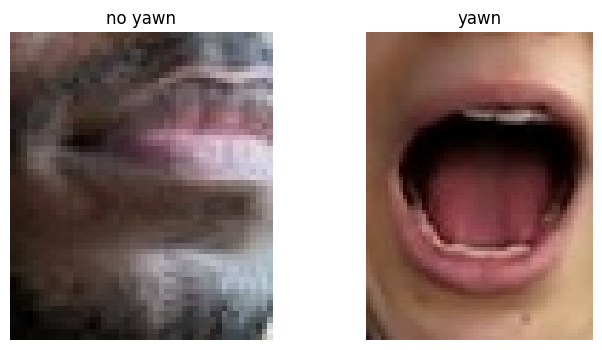

In [58]:
import matplotlib.pyplot as plt
import cv2
import random

classes = ["no yawn", "yawn"]

plt.figure(figsize=(8, 4))

for i, class_name in enumerate(classes):
    class_path = os.path.join(dataset_path, class_name)

    image_name = random.choice(os.listdir(class_path))
    image_path = os.path.join(class_path, image_name)

    img = cv2.imread(image_path)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(1, 2, i + 1)
    plt.imshow(img)
    plt.title(class_name)
    plt.axis("off")

plt.show()

In [14]:
from PIL import Image

bad_files = []

for class_name in classes:
    class_path = os.path.join(dataset_path, class_name)

    for file in os.listdir(class_path):
        file_path = os.path.join(class_path, file)

        try:
            img = Image.open(file_path)
            img.verify()
        except:
            bad_files.append(file_path)

print("Corrupted files:", len(bad_files))

Corrupted files: 0


In [15]:
!pip install split-folders

In [16]:
import splitfolders

splitfolders.ratio(
    dataset_path,
    output="/content/yawn_split",
    seed=42,
    ratio=(0.70, 0.15, 0.15)
)

Copying files: 5119 files [00:01, 5026.55 files/s]


In [17]:
for split in ["train", "val", "test"]:
    print("\n", split)

    split_path = f"/content/yawn_split/{split}"

    for folder in os.listdir(split_path):
        folder_path = os.path.join(split_path, folder)
        print(folder, len(os.listdir(folder_path)))


 train
no yawn 1813
yawn 1769

 val
no yawn 388
yawn 379

 test
no yawn 390
yawn 380


In [19]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/yawn_split/train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=True,
    seed=42
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/yawn_split/val",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    "/content/yawn_split/test",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="binary",
    shuffle=False
)

print(train_ds.class_names)

Found 3582 files belonging to 2 classes.
Found 767 files belonging to 2 classes.
Found 770 files belonging to 2 classes.
['no yawn', 'yawn']


In [20]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

In [21]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomContrast(0.10)
])

In [22]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [23]:
inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dropout(0.3)(x)

outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid"
)(x)

model = tf.keras.Model(inputs, outputs)

In [24]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall")
    ]
)

In [25]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=2
    ),

    tf.keras.callbacks.ModelCheckpoint(
        "/content/best_yawn_model.keras",
        monitor="val_loss",
        save_best_only=True
    )
]

In [28]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks
)

Epoch 1/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 281s 2s/step - accuracy: 0.9757 - loss: 0.0724 - precision: 0.9806 - recall: 0.9700 - val_accuracy: 0.9817 - val_loss: 0.0757 - val_precision: 0.9841 - val_recall: 0.9789 - learning_rate: 6.2500e-05
Epoch 2/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 249s 2s/step - accuracy: 0.9779 - loss: 0.0672 - precision: 0.9834 - recall: 0.9717 - val_accuracy: 0.9817 - val_loss: 0.0759 - val_precision: 0.9841 - val_recall: 0.9789 - learning_rate: 6.2500e-05
Epoch 3/15
112/112 ━━━━━━━━━━━━━━━━━━━━ 250s 2s/step - accuracy: 0.9810 - loss: 0.0659 - precision: 0.9863 - recall: 0.9751 - val_accuracy: 0.9817 - val_loss: 0.0758 - val_precision: 0.9841 - val_recall: 0.9789 - learning_rate: 3.1250e-05


In [29]:
model = tf.keras.models.load_model(
    "/content/best_yawn_model.keras"
)

In [30]:
test_results = model.evaluate(test_ds)

print(test_results)

25/25 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.9792 - loss: 0.0715 - precision: 0.9840 - recall: 0.9737
[0.07148297876119614, 0.9792208075523376, 0.9840425252914429, 0.9736841917037964]


In [31]:
import numpy as np

pred_probs = model.predict(test_ds)

pred_labels = (
    pred_probs.flatten() >= 0.5
).astype(int)

25/25 ━━━━━━━━━━━━━━━━━━━━ 42s 2s/step


In [32]:
true_labels = np.concatenate([
    y.numpy() for x, y in test_ds
]).astype(int).flatten()

[[384   6]
 [ 10 370]]


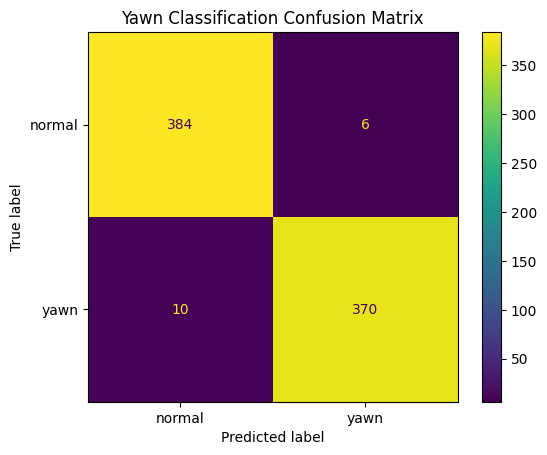

In [33]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    true_labels,
    pred_labels
)

print(cm)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["normal", "yawn"]
).plot()

plt.title("Yawn Classification Confusion Matrix")
plt.show()

In [34]:
from sklearn.metrics import classification_report

print(
    classification_report(
        true_labels,
        pred_labels,
        target_names=["normal", "yawn"]
    )
)

              precision    recall  f1-score   support

      normal       0.97      0.98      0.98       390
        yawn       0.98      0.97      0.98       380

    accuracy                           0.98       770
   macro avg       0.98      0.98      0.98       770
weighted avg       0.98      0.98      0.98       770



In [37]:
predicted_class = (
    "yawn"
    if prediction >= 0.5
    else "no yawn"
)

In [38]:
if predicted_class == actual_class:
    correct += 1

In [42]:
import os
import random
import numpy as np
from tensorflow.keras.utils import load_img, img_to_array

correct = 0
total = 20

for i in range(total):

    actual_class = random.choice(["no yawn", "yawn"])

    folder = f"/content/yawn_split/test/{actual_class}"

    image_name = random.choice(os.listdir(folder))
    image_path = os.path.join(folder, image_name)

    img = load_img(
        image_path,
        target_size=(224, 224)
    )

    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)

    prediction = model.predict(
        img_array,
        verbose=0
    )[0][0]

    if prediction >= 0.5:
        predicted_class = "yawn"
    else:
        predicted_class = "no yawn"

    if predicted_class == actual_class:
        correct += 1

    print(
        f"{i+1}. Actual: {actual_class} | "
        f"Predicted: {predicted_class} | "
        f"Probability: {prediction:.4f}"
    )

print("\nCorrect:", correct, "/", total)

1. Actual: yawn | Predicted: yawn | Probability: 0.5019
2. Actual: yawn | Predicted: yawn | Probability: 0.9997
3. Actual: yawn | Predicted: yawn | Probability: 0.9504
4. Actual: no yawn | Predicted: yawn | Probability: 0.6080
5. Actual: yawn | Predicted: yawn | Probability: 0.9999
6. Actual: no yawn | Predicted: no yawn | Probability: 0.1603
7. Actual: yawn | Predicted: yawn | Probability: 0.9996
8. Actual: no yawn | Predicted: yawn | Probability: 0.9446
9. Actual: no yawn | Predicted: yawn | Probability: 0.9732
10. Actual: no yawn | Predicted: no yawn | Probability: 0.1388
11. Actual: yawn | Predicted: yawn | Probability: 0.9960
12. Actual: yawn | Predicted: yawn | Probability: 1.0000
13. Actual: no yawn | Predicted: no yawn | Probability: 0.2702
14. Actual: yawn | Predicted: yawn | Probability: 0.9997
15. Actual: yawn | Predicted: yawn | Probability: 0.9996
16. Actual: no yawn | Predicted: no yawn | Probability: 0.3297
17. Actual: yawn | Predicted: yawn | Probability: 0.9997
18. Act

In [50]:
threshold = 0.6

In [49]:
thresholds = [ 0.6, 0.7, 0.8]

In [51]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

for t in thresholds:
    preds = (pred_probs.flatten() >= t).astype(int)

    acc = accuracy_score(true_labels, preds)
    precision = precision_score(true_labels, preds)
    recall = recall_score(true_labels, preds)
    f1 = f1_score(true_labels, preds)

    print(
        f"Threshold {t:.2f} | "
        f"Accuracy: {acc:.4f} | "
        f"Yawn Precision: {precision:.4f} | "
        f"Yawn Recall: {recall:.4f} | "
        f"F1: {f1:.4f}"
    )

Threshold 0.60 | Accuracy: 0.9805 | Yawn Precision: 0.9946 | Yawn Recall: 0.9658 | F1: 0.9800
Threshold 0.70 | Accuracy: 0.9766 | Yawn Precision: 0.9945 | Yawn Recall: 0.9579 | F1: 0.9759
Threshold 0.80 | Accuracy: 0.9688 | Yawn Precision: 0.9944 | Yawn Recall: 0.9421 | F1: 0.9676


In [53]:
from google.colab import files

files.download("/content/yawn_state_mobilenetv2.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [55]:
from google.colab import files
files.download("/content/best_yawn_model.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [54]:
import os
save_dir = "/content/drive/MyDrive/driver_drowsiness"
os.makedirs(save_dir, exist_ok=True)
model.save("/content/yawn_state_mobilenetv2.keras")